In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
column_names = [
    "mpg", "cylinders", "displacement", "horsepower", 
    "weight", "acceleration", "model_year", "origin", "car_name"
]

df = pd.read_csv(url, names=column_names, sep=r'\s+', na_values="?")

df["horsepower"] = pd.to_numeric(df["horsepower"])
df.dropna(subset=["horsepower"], inplace=True)

df["origin_label"] = df["origin"].map({1: "USA", 2: "Europe", 3: "Japan"})

num_cols = ["mpg", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_cols = ["origin_label", "cylinders"]

print(f"Data successfully loaded. Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Data successfully loaded. Shape: 392 rows, 10 columns


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,origin_label
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu,USA
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320,USA
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite,USA
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst,USA
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino,USA


In [5]:
stats_summary = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    
    stats_summary.append({
        "Attribute": col,
        "Min": round(df[col].min(), 2),
        "Max": round(df[col].max(), 2),
        "Mean": round(df[col].mean(), 2),
        "Median": round(df[col].median(), 2),
        "IQR Outlier Count": int(outliers)
    })

stats_df = pd.DataFrame(stats_summary)
stats_df

,Attribute,Min,Max,Mean,Median,IQR Outlier Count
0,mpg,9.0,46.6,23.45,22.75,0
1,displacement,68.0,455.0,194.41,151.00,0
2,horsepower,46.0,230.0,104.47,93.50,10
3,weight,1613.0,5140.0,2977.58,2803.50,0
4,acceleration,8.0,24.8,15.54,15.50,11
5,model_year,70.0,82.0,75.98,76.00,0


### Summary Statistics & Distribution Observations
- **Center & Skewness:**
  - `displacement` (Mean: 194.41, Median: 151.0) and `horsepower` (Mean: 104.47, Median: 93.5) exhibit substantial right-skewness, as evidenced by means notably higher than their medians.
  - `acceleration` (Mean: 15.54, Median: 15.5) shows near-perfect symmetry, closely resembling a Gaussian distribution.
- **Outlier Assessment ($1.5 \times \text{IQR}$):**
  - `horsepower` contains several upper-tail outliers corresponding to high-performance V8 engines (>200 hp).
  - `acceleration` exhibits minor outliers at both the lower (drag-strip capable) and upper (sluggish) extremes.
  - `mpg`, `displacement`, `weight`, and `model_year` display no severe IQR outliers.

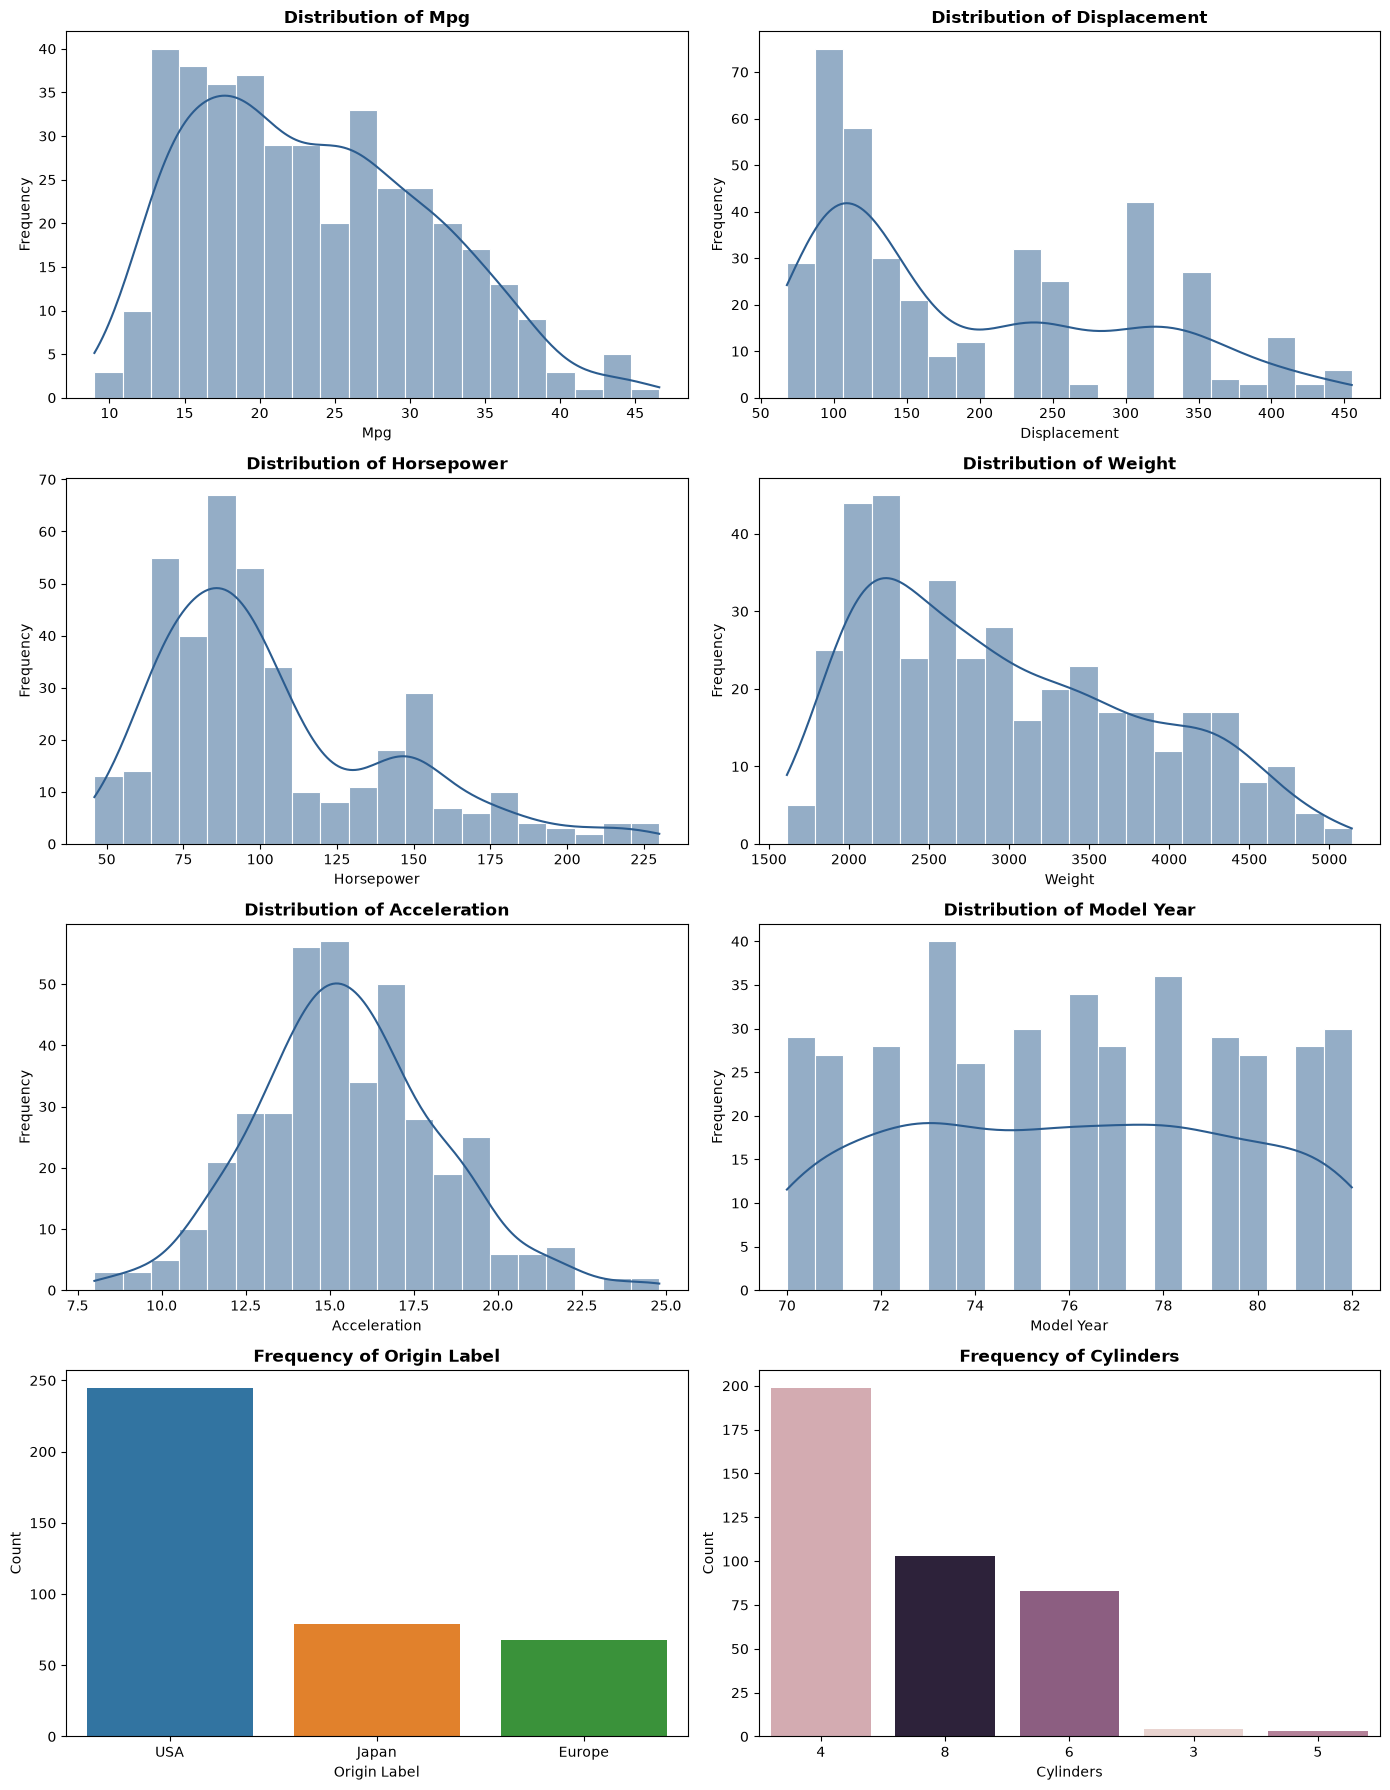

In [8]:
# -------------------------------------------------------------------------
# 1-Dimensional Distributions: Histograms (Numerical) & Bar Charts (Categorical)
# -------------------------------------------------------------------------

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 18))
axes = axes.flatten()

# Plot numerical variables as histograms with KDE curves
for idx, col in enumerate(num_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[idx],
        color="#2b5c8f",
        bins=20,
        edgecolor="white",
        linewidth=0.8
    )
    axes[idx].set_title(f"Distribution of {col.replace('_', ' ').title()}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel(col.replace('_', ' ').title())
    axes[idx].set_ylabel("Frequency")

# Plot categorical variables as frequency bar charts
cat_to_plot = ["origin_label", "cylinders"]
for idx, col in enumerate(cat_to_plot, start=len(num_cols)):
    order = df[col].value_counts().index
    sns.countplot(
        data=df,
        x=col,
        hue = col, 
        legend = None,
        order=order,
        ax=axes[idx],
    )
    axes[idx].set_title(f"Frequency of {col.replace('_', ' ').title()}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel(col.replace('_', ' ').title())
    axes[idx].set_ylabel("Count")

plt.tight_layout()
plt.show()